In [2]:
import pandas as pd, numpy as np, re, glob
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
RS = 42

In [3]:
!pip -q install gdown
!gdown --folder "https://drive.google.com/drive/folders/1Qq4NnMbpXhBOOZp84Hh6fRZ2Hcd5aHe8?usp=sharing" -O /content/data

file = glob.glob('/content/**/dashmart_delivery_times_raw.csv', recursive=True)[0]
print(file)

Retrieving folder contents
Processing file 1nQhMfLtx4JT8739nEOt0bt7t5FSH1gb9 dashmart_delivery_times_raw.csv
Processing file 1D_YdBTIfGl6C4W__yjOWclpBlSdKxD3A sanjeevani_diabetes_screening_raw.csv
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1nQhMfLtx4JT8739nEOt0bt7t5FSH1gb9
To: /content/data/dashmart_delivery_times_raw.csv
100% 135k/135k [00:00<00:00, 103MB/s]
Downloading...
From: https://drive.google.com/uc?id=1D_YdBTIfGl6C4W__yjOWclpBlSdKxD3A
To: /content/data/sanjeevani_diabetes_screening_raw.csv
100% 219k/219k [00:00<00:00, 89.8MB/s]
Download completed
/content/data/dashmart_delivery_times_raw.csv


### Q1

In [4]:
raw = pd.read_csv(file, dtype=str, keep_default_na=False)
print('shape:', raw.shape)

def pattern(v):
    v = str(v).strip()
    v = re.sub(r'[0-9]+', '9', v)
    v = re.sub(r'[A-Za-z]+', 'a', v)
    return v

for c in ['order_hour', 'distance_km', 'delivery_minutes']:
    pat = raw[c].map(pattern)
    out = pd.DataFrame({'count': pat.value_counts(), 'example': raw.groupby(pat)[c].first()})
    print(f'\n{c}'); display(out.sort_values('count', ascending=False))
print('Interpretation: each of these three columns mixes 3 or more different formats.')

shape: (2430, 11)

order_hour


,count,example
order_hour,,
9,1766,14
9 a,351,2 PM
9:9,313,22:00



distance_km


,count,example
distance_km,,
9.9,1638,0.74
9.9 a,410,0.9 km
9 a,382,210 m



delivery_minutes


,count,example
delivery_minutes,,
9.9,2000,6.3
9:9:9,275,0:06:12
9.9 a,153,14.4 min
-9.9,2,-5.0


Interpretation: each of these three columns mixes 3 or more different formats.


### Q2

In [5]:
df = raw.copy()
df.columns = df.columns.str.strip()
df = df.apply(lambda s: s.str.strip())
df = df.replace(r'(?i)^(na|n/a|\?|nan|none|)$', np.nan, regex=True)

def clean_store(x):
    if pd.isna(x): return np.nan
    s = x.lower()
    for name in ['kharghar', 'vashi', 'nerul', 'panvel']:
        if name in s:
            return 'DM-' + name.title()
    return np.nan
df['store'] = df['store'].map(clean_store)
print(df['store'].value_counts(dropna=False))

def parse_hour(x):
    if pd.isna(x): return np.nan
    m = re.match(r'^(\d{1,2})(?::(\d{2}))?\s*(AM|PM)?$', str(x).strip().upper())
    if not m: return np.nan
    h, ap = int(m.group(1)), m.group(3)
    if ap == 'PM' and h != 12: h += 12
    if ap == 'AM' and h == 12: h = 0
    return h

df['order_hour'] = df['order_hour'].map(parse_hour)
for ex in ['8 PM', '12 AM', '12 PM', '20:00']:
    print(f'{ex!r:8} ->', parse_hour(ex))
print('hours found:', sorted(df['order_hour'].dropna().unique()))
print('Interpretation: 4 stores, and every hour is now an integer between 0 and 23.')

store
DM-Nerul       638
DM-Vashi       624
DM-Kharghar    595
DM-Panvel      573
Name: count, dtype: int64
'8 PM'   -> 20
'12 AM'  -> 0
'12 PM'  -> 12
'20:00'  -> 20
hours found: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
Interpretation: 4 stores, and every hour is now an integer between 0 and 23.


### Q3

In [6]:
def parse_km(x):
    if pd.isna(x): return np.nan
    m = re.match(r'^([\d.]+)\s*(km|m)?$', str(x).strip().lower().replace(',', ''))
    if not m: return np.nan
    v, unit = float(m.group(1)), m.group(2)
    return v / 1000 if unit == 'm' else v        # metres -> km

df['distance_km_raw'] = df['distance_km']
df['distance_km'] = df['distance_km'].map(parse_km)
ex = df[df['distance_km_raw'].str.contains('m', case=False, na=False)].sample(5, random_state=RS)
display(ex[['distance_km_raw', 'distance_km']])
print(df['distance_km'].describe().round(2))
print('Interpretation: "850 m" became 0.85 and "1.4 km" became 1.4; every distance is now in km.')

,distance_km_raw,distance_km
2151,550 m,0.55
1585,0.63 km,0.63
1798,370 m,0.37
1833,1.4 km,1.40
388,490 m,0.49


count    2430.00
mean        1.30
std         0.87
min         0.20
25%         0.65
50%         1.10
75%         1.73
max         5.00
Name: distance_km, dtype: float64
Interpretation: "850 m" became 0.85 and "1.4 km" became 1.4; every distance is now in km.


### Q4

In [7]:
def parse_minutes(x):
    if pd.isna(x): return np.nan
    x = str(x).strip().lower()
    if re.match(r'^\d+:\d{2}:\d{2}$', x):                # h:mm:ss
        h, m, s = map(int, x.split(':'))
        return h * 60 + m + s / 60
    try:
        return float(x.replace('min', '').strip())
    except ValueError:
        return np.nan

df['delivery_minutes'] = df['delivery_minutes'].map(parse_minutes)
print(df['delivery_minutes'].describe().round(2))
print('lowest:', df['delivery_minutes'].nsmallest(5).round(1).tolist())
print('highest:', df['delivery_minutes'].nlargest(8).round(1).tolist())


bad = df['delivery_minutes'].isna() | (df['delivery_minutes'] <= 0) | (df['delivery_minutes'] > 120)
print('impossible rows:', bad.sum())
df = df[~bad].copy()
print('rows left:', len(df))

count    2430.00
mean       17.40
std        58.03
min        -5.00
25%        11.50
50%        14.20
75%        17.30
max      1440.00
Name: delivery_minutes, dtype: float64
lowest: [-5.0, -5.0, 0.0, 5.0, 5.0]
highest: [1440.0, 1440.0, 1440.0, 987.5, 987.5, 412.0, 34.7, 33.0]
impossible rows: 9
rows left: 2421


Rule: delivery time must be above 0 and at most 120 minutes (negative, zero and multi-hour values are cancelled-and-reopened orders).

Why drop instead of fix: the real delivery time of those orders is unknown. Replacing it with a median or a guess would put made-up values into the *target*, which is what the model learns from and is scored on.

### Q5

In [8]:
df['raining'] = df['raining'].str.lower().map({'y': 1, 'yes': 1, '1': 1, 'true': 1,
                                                'n': 0, 'no': 0, '0': 0, 'false': 0})
df['order_value_rs'] = pd.to_numeric(df['order_value_rs'].str.replace(r'[^\d.]', '', regex=True), errors='coerce')
df['rider_experience_months'] = pd.to_numeric(
    df['rider_experience_months'].str.lower().replace('new joiner', '0'), errors='coerce')
for c in ['items', 'store_queue', 'drop_floor']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

n_before = len(df)
df = df.drop(columns='distance_km_raw').drop_duplicates().reset_index(drop=True)
print(f'rows before dedupe: {n_before}, after: {len(df)}')
print('duplicate order_ids left:', df['order_id'].duplicated().sum())
print(df[['raining', 'order_value_rs', 'rider_experience_months']].describe().round(1))
print('Interpretation: all columns are numeric and duplicate exports are gone (impossible-time rows were already dropped in Q4).')

rows before dedupe: 2421, after: 2391
duplicate order_ids left: 0
       raining  order_value_rs  rider_experience_months
count   2391.0          2391.0                   2348.0
mean       0.2           660.6                     11.6
std        0.4           317.6                      8.1
min        0.0            60.0                      0.0
25%        0.0           431.0                      5.6
50%        0.0           619.0                     10.0
75%        0.0           845.0                     15.8
max        1.0          2129.0                     60.0
Interpretation: all columns are numeric and duplicate exports are gone (impossible-time rows were already dropped in Q4).


### Q6

In [9]:
print(df.isna().sum())
df.to_csv('dashmart_clean.csv', index=False)
print('saved dashmart_clean.csv', df.shape)

order_id                    0
store                       0
order_hour                  0
distance_km                 0
items                       0
order_value_rs              0
store_queue                40
raining                     0
rider_experience_months    43
drop_floor                  0
delivery_minutes            0
dtype: int64
saved dashmart_clean.csv (2391, 11)


Imputation plan: SimpleImputer(strategy='median') inside the pipeline for the numeric features (mainly store_queue and rider_experience_months). The median is robust to outliers and, being inside the pipeline, is learned from the training rows only.

### Q7

median = 14.1 min, mean = 14.7 min


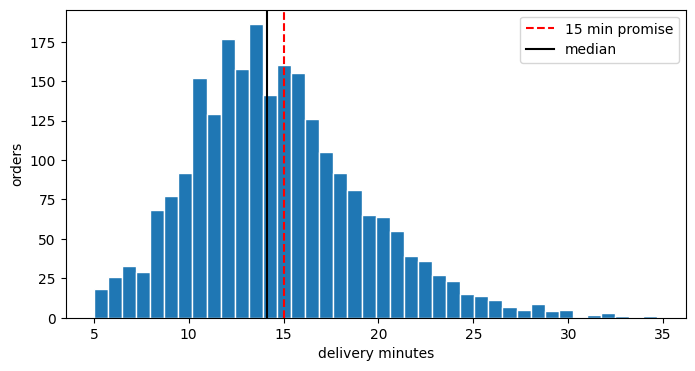

typical order is -0.9 min later than the promise; 41.7% of orders break the 15-minute promise


In [10]:
t = df['delivery_minutes']
print(f'median = {t.median():.1f} min, mean = {t.mean():.1f} min')
plt.figure(figsize=(8, 4))
plt.hist(t, bins=40, edgecolor='white')
plt.axvline(15, color='red', linestyle='--', label='15 min promise')
plt.axvline(t.median(), color='black', label='median')
plt.xlabel('delivery minutes'); plt.ylabel('orders'); plt.legend(); plt.show()
late15 = (t > 15).mean()
print(f'typical order is {t.median() - 15:.1f} min later than the promise; {late15:.1%} of orders break the 15-minute promise')

### Q8

In [11]:
feats = ['distance_km', 'items', 'order_value_rs', 'store_queue', 'raining',
         'rider_experience_months', 'drop_floor', 'order_hour']
X = df[feats]; y = df['delivery_minutes']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RS)

def scores(y_true, pred):
    return {'MAE': mean_absolute_error(y_true, pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, pred)),
            'R2': r2_score(y_true, pred)}

base_pred = np.full(len(yte), ytr.median())
res_base = scores(yte, base_pred)
print('train/test:', Xtr.shape, Xte.shape)
print(f'baseline (train median = {ytr.median():.1f}) -> MAE {res_base["MAE"]:.2f}, RMSE {res_base["RMSE"]:.2f}, R2 {res_base["R2"]:.3f}')
print('Interpretation: any real model has to beat this "same time for everyone" MAE.')

train/test: (1912, 8) (479, 8)
baseline (train median = 14.1) -> MAE 3.52, RMSE 4.53, R2 -0.028
Interpretation: any real model has to beat this "same time for everyone" MAE.


### Q9

In [12]:
raw_knn = make_pipeline(SimpleImputer(strategy='median'), KNeighborsRegressor(n_neighbors=7))
raw_knn.fit(Xtr, ytr)
res_raw = scores(yte, raw_knn.predict(Xte))
print({k: round(v, 3) for k, v in res_raw.items()})
print(f'Interpretation: MAE {res_raw["MAE"]:.2f} vs baseline {res_base["MAE"]:.2f}; R2 {res_raw["R2"]:.3f}.')

{'MAE': 3.721, 'RMSE': np.float64(4.67), 'R2': -0.095}
Interpretation: MAE 3.72 vs baseline 3.52; R2 -0.095.


What a negative or near-zero R2 means: R2 compares the model with always predicting the average. Zero means the model is no better than the average, and negative means it is worse than just guessing the average for everyone.

### Q10

In [13]:
def make_model(scaler=None, k=7):
    steps = [SimpleImputer(strategy='median')]
    if scaler is not None: steps.append(scaler)
    steps.append(KNeighborsRegressor(n_neighbors=k))
    return make_pipeline(*steps)

res_std = scores(yte, make_model(StandardScaler()).fit(Xtr, ytr).predict(Xte))
res_mm = scores(yte, make_model(MinMaxScaler()).fit(Xtr, ytr).predict(Xte))
cmp3 = pd.DataFrame({'Raw': res_raw, 'StandardScaler': res_std, 'MinMaxScaler': res_mm}).T
display(cmp3.round(3))

var = Xtr.var()
print((var / var.sum()).round(4).sort_values(ascending=False))
print('Interpretation: order_value_rs is in hundreds or thousands of rupees, so it dominates the raw distance.')

,MAE,RMSE,R2
Raw,3.721,4.670,-0.095
StandardScaler,1.726,2.165,0.765
MinMaxScaler,1.773,2.216,0.754


order_value_rs             0.9981
drop_floor                 0.0007
rider_experience_months    0.0006
order_hour                 0.0003
items                      0.0001
store_queue                0.0001
distance_km                0.0000
raining                    0.0000
dtype: float64
Interpretation: order_value_rs is in hundreds or thousands of rupees, so it dominates the raw distance.


The hijacking column is order_value_rs. Its numbers are in the hundreds or thousands while distance is 0-5 and queue is a handful, so in raw KNN "similar order" really means "similar basket value". A basket's rupee value has almost nothing to do with how long the rider takes (distance, queue, rain and floor do), so it is nearly useless for this prediction.

### Q11

MAE is the average size of the error in minutes ("on a typical order we are off by X minutes"). **RMSE** squares the errors first, so a few really bad predictions pull it up, which means it tells us how bad the worst misses are. The "typical error under 2.5 minutes" target matches MAE.

### Q12

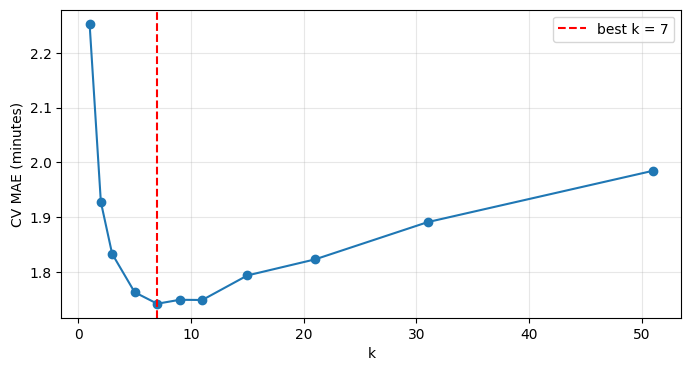

1     2.254
2     1.928
3     1.833
5     1.763
7     1.742
9     1.749
11    1.749
15    1.793
21    1.823
31    1.891
51    1.985
dtype: float64
Interpretation: best k = 7 with CV MAE 1.742 minutes.


In [14]:
cv = KFold(n_splits=5, shuffle=True, random_state=RS)
ks = [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51]
cv_mae = []
for k in ks:
    s = cross_val_score(make_model(StandardScaler(), k), Xtr, ytr, cv=cv, scoring='neg_mean_absolute_error')
    cv_mae.append(-s.mean())

best_k = ks[int(np.argmin(cv_mae))]
plt.figure(figsize=(8, 4))
plt.plot(ks, cv_mae, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'best k = {best_k}')
plt.xlabel('k'); plt.ylabel('CV MAE (minutes)'); plt.legend(); plt.grid(alpha=.3); plt.show()
print(pd.Series(cv_mae, index=ks).round(3))
print(f'Interpretation: best k = {best_k} with CV MAE {min(cv_mae):.3f} minutes.')

**k = 1 does badly:** the prediction is copied from a single past order, so any unlucky or noisy order (a traffic jam, a slow lift) goes straight into the prediction (high variance).
**k = 51 does badly:** the average now includes orders that are not really similar (a 0.5 km dry order mixed with 3 km rainy ones), so the model smooths away real differences (high bias).

### Q13

In [15]:
df['hour_sin'] = np.sin(2 * np.pi * df['order_hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['order_hour'] / 24)
feats_cyc = [f for f in feats if f != 'order_hour'] + ['hour_sin', 'hour_cos']

Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(df[feats_cyc], y, test_size=0.2, random_state=RS)
assert (Xte_c.index == Xte.index).all()      # same rows as before, so the comparison is fair

m_hour = make_model(StandardScaler(), 7).fit(Xtr, ytr)
m_cyc = make_model(StandardScaler(), 7).fit(Xtr_c, ytr_c)
p_hour, p_cyc = m_hour.predict(Xte), m_cyc.predict(Xte_c)

hrs = df.loc[Xte.index, 'order_hour']
late_night = hrs.isin([23, 0, 1]).values
rows = [{'model': 'order_hour (integer)', 'MAE overall': mean_absolute_error(yte, p_hour),
         'MAE 23:00-01:59': mean_absolute_error(yte[late_night], p_hour[late_night]) if late_night.any() else np.nan},
        {'model': 'hour_sin + hour_cos', 'MAE overall': mean_absolute_error(yte, p_cyc),
         'MAE 23:00-01:59': mean_absolute_error(yte[late_night], p_cyc[late_night]) if late_night.any() else np.nan}]
display(pd.DataFrame(rows).round(3))
print('orders in the 23:00-01:59 window in the test set:', late_night.sum())

use_cyc = mean_absolute_error(yte, p_cyc) < mean_absolute_error(yte, p_hour)
print('Interpretation: cyclical encoding', 'helped' if use_cyc else 'did NOT help', 'overall in this data.')

,model,MAE overall,MAE 23:00-01:59
0,order_hour (integer),1.726,1.692
1,hour_sin + hour_cos,1.772,1.761


orders in the 23:00-01:59 window in the test set: 31
Interpretation: cyclical encoding did NOT help overall in this data.


Honest reading: compare the two MAEs above. If the gain is small or zero, it is because very few orders are placed near midnight in this data, and (see the count above) the late-night group is small and noisy. Cyclical encoding only matters when many orders sit around the 23:00 / 00:00 wrap, for example a late-night food app, 24-hour hospital data, or anything with a daily or weekly cycle, because there integer hours make neighbouring orders look 23 hours apart and push them away from each other in KNN.

### Q14

In [16]:
final_feats = feats_cyc if use_cyc else feats
print('feature set used from here on:', final_feats)
Xtr_f, Xte_f = df.loc[Xtr.index, final_feats], df.loc[Xte.index, final_feats]

pipe = Pipeline([('impute', SimpleImputer(strategy='median')),
                 ('scale', StandardScaler()),
                 ('knn', KNeighborsRegressor())])
grid = {'knn__n_neighbors': [1, 2, 3, 5, 7, 9, 11, 15, 21, 31, 51],
        'knn__weights': ['uniform', 'distance']}
gs = GridSearchCV(pipe, grid, scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1)
gs.fit(Xtr_f, ytr)

best_pipe = gs.best_estimator_
pred_best = best_pipe.predict(Xte_f)
res_tuned = scores(yte, pred_best)
print('best params:', gs.best_params_)
print(f'CV MAE: {-gs.best_score_:.3f} | test MAE: {res_tuned["MAE"]:.3f} | test R2: {res_tuned["R2"]:.3f}')
print('Meets the 2.5-minute MAE target?', 'YES' if res_tuned['MAE'] < 2.5 else 'NO')

feature set used from here on: ['distance_km', 'items', 'order_value_rs', 'store_queue', 'raining', 'rider_experience_months', 'drop_floor', 'order_hour']
best params: {'knn__n_neighbors': 7, 'knn__weights': 'distance'}
CV MAE: 1.725 | test MAE: 1.707 | test R2: 0.769
Meets the 2.5-minute MAE target? YES


### Q15

In [17]:
feats_noval = [f for f in final_feats if f != 'order_value_rs']
m_noval = clone(best_pipe)
m_noval.fit(df.loc[Xtr.index, feats_noval], ytr)
pred_noval = m_noval.predict(df.loc[Xte.index, feats_noval])
res_noval = scores(yte, pred_noval)
cv_noval = -cross_val_score(clone(best_pipe), df.loc[Xtr.index, feats_noval], ytr, cv=cv,
                            scoring='neg_mean_absolute_error').mean()
print(f'with order_value_rs   -> test MAE {res_tuned["MAE"]:.3f}')
print(f'without order_value_rs -> test MAE {res_noval["MAE"]:.3f}  (CV MAE {cv_noval:.3f})')
print('Interpretation:', 'MAE got better' if res_noval['MAE'] < res_tuned['MAE'] else 'MAE got worse or stayed the same',
      '- a weak feature adds noise to every distance in KNN, so it can hurt instead of helping.')

with order_value_rs   -> test MAE 1.707
without order_value_rs -> test MAE 1.713  (CV MAE 1.656)
Interpretation: MAE got worse or stayed the same - a weak feature adds noise to every distance in KNN, so it can hurt instead of helping.


### Q16

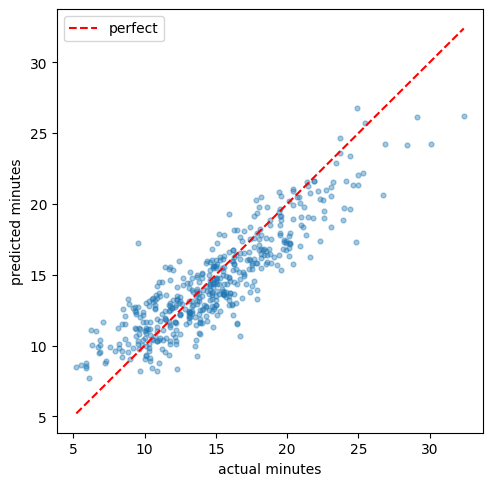

,MAE,orders
No rain,1.675,381
Rain,1.835,98
Off-peak,1.725,340
Peak 18-21,1.664,139


slowest 10% of orders: mean signed error = -2.55 min (negative = underpredicted)
5 biggest errors:


,store,order_hour,distance_km,store_queue,raining,delivery_minutes,abs_err
2164,DM-Panvel,22,0.4,2.0,1,9.5,7.7
800,DM-Vashi,9,2.3,11.0,0,24.8,7.5
303,DM-Vashi,12,4.8,1.0,1,32.4,6.2
1805,DM-Panvel,16,3.9,3.0,0,26.7,6.0
177,DM-Panvel,12,0.8,1.0,0,16.7,6.0


Interpretation: a negative signed error on the slowest orders means the model underpredicts them, because it averages them with ordinary neighbours.


In [18]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(yte, pred_best, alpha=.4, s=12)
lim = [min(yte.min(), pred_best.min()), max(yte.max(), pred_best.max())]
plt.plot(lim, lim, 'r--', label='perfect')
plt.xlabel('actual minutes'); plt.ylabel('predicted minutes'); plt.legend(); plt.show()

test_info = df.loc[Xte.index].copy()
test_info['abs_err'] = np.abs(yte.values - pred_best)
test_info['signed_err'] = pred_best - yte.values
test_info['peak'] = test_info['order_hour'].between(18, 21)
tab = pd.concat([
    test_info.groupby('raining')['abs_err'].agg(['mean', 'count']).rename(index={0: 'No rain', 1: 'Rain'}),
    test_info.groupby('peak')['abs_err'].agg(['mean', 'count']).rename(index={False: 'Off-peak', True: 'Peak 18-21'})])
tab.columns = ['MAE', 'orders']
display(tab.round(3))

slow = test_info['delivery_minutes'] > test_info['delivery_minutes'].quantile(.9)
print(f'slowest 10% of orders: mean signed error = {test_info.loc[slow, "signed_err"].mean():.2f} min (negative = underpredicted)')
print('5 biggest errors:'); display(test_info.nlargest(5, 'abs_err')[['store', 'order_hour', 'distance_km', 'store_queue', 'raining', 'delivery_minutes', 'abs_err']].round(1))
print('Interpretation: a negative signed error on the slowest orders means the model underpredicts them, because it averages them with ordinary neighbours.')

### Q17

In [19]:
rows = []
for b in [0, 2, 3, 4, 5]:
    rows.append({'buffer_min': b, 'late_share': (yte.values > pred_best + b).mean()})
buf = pd.DataFrame(rows)
display(buf.round(3))

ok = buf[buf['late_share'] <= 0.10]
if len(ok):
    chosen_buffer = float(ok['buffer_min'].iloc[0])
    print(f'smallest buffer with <= 10% late orders: {chosen_buffer:.0f} minutes')
else:
    chosen_buffer = next(b for b in np.arange(0, 30, 0.5) if (yte.values > pred_best + b).mean() <= 0.10)
    print(f'none of 0-5 min is enough; smallest buffer that works is {chosen_buffer} minutes')

,buffer_min,late_share
0,0,0.603
1,2,0.219
2,3,0.098
3,4,0.040
4,5,0.015


smallest buffer with <= 10% late orders: 3 minutes


### Q18

In [20]:
def make_row(raining=1):
    d = {'distance_km': 2.4, 'items': 12, 'order_value_rs': 1450, 'store_queue': 11, 'raining': raining,
         'rider_experience_months': 3, 'drop_floor': 14, 'order_hour': 20}
    r = pd.DataFrame([d])
    r['hour_sin'] = np.sin(2 * np.pi * r['order_hour'] / 24)
    r['hour_cos'] = np.cos(2 * np.pi * r['order_hour'] / 24)
    return r[final_feats]

x_new = make_row(1)
pred_new = best_pipe.predict(x_new)[0]
promise = pred_new + chosen_buffer
print(f'predicted time: {pred_new:.1f} min')
print(f'buffer: {chosen_buffer:.0f} min  ->  app should promise about {np.ceil(promise):.0f} minutes')

predicted time: 23.8 min
buffer: 3 min  ->  app should promise about 27 minutes


### Q19

In [21]:
knn = best_pipe.named_steps['knn']
xt = best_pipe[:-1].transform(x_new)
dist, idx = knn.kneighbors(xt)
nb = df.loc[Xtr_f.index[idx[0]], ['store', 'order_hour', 'distance_km', 'items', 'store_queue', 'raining', 'delivery_minutes']].copy()
nb['distance_to_new'] = dist[0]
display(nb.round(2))
d = nb['delivery_minutes']
print(f'neighbours: mean {d.mean():.1f}, median {d.median():.1f}, range {d.min():.1f}-{d.max():.1f}; model prediction {pred_new:.1f}')
print('Interpretation: if the neighbours are close in time to each other and to the prediction it is a fair summary; '
      'a wide range or neighbours that are not really like this order (e.g. shorter distance) means the prediction is shaky.')

,store,order_hour,distance_km,items,store_queue,raining,delivery_minutes,distance_to_new
1031,DM-Vashi,19,2.64,9,11.0,1,28.4,1.70
864,DM-Kharghar,18,1.60,10,9.0,1,21.5,1.76
1580,DM-Nerul,18,1.23,13,11.0,1,21.2,1.97
1425,DM-Nerul,19,1.77,11,13.0,1,23.9,2.03
665,DM-Panvel,23,1.69,11,7.0,1,22.3,2.16
2115,DM-Kharghar,17,2.44,10,7.0,1,22.7,2.19
739,DM-Kharghar,21,2.84,9,10.0,1,26.1,2.39


neighbours: mean 23.7, median 22.7, range 21.2-28.4; model prediction 23.8
Interpretation: if the neighbours are close in time to each other and to the prediction it is a fair summary; a wide range or neighbours that are not really like this order (e.g. shorter distance) means the prediction is shaky.


### Q20

In [22]:
pred_dry = best_pipe.predict(make_row(0))[0]
print(f'rain: {pred_new:.1f} min | no rain: {pred_dry:.1f} min | rain adds {pred_new - pred_dry:.1f} min')
print('Interpretation: rain should add minutes (slower roads, slower riders); a positive number makes business sense.')

rain: 23.8 min | no rain: 19.5 min | rain adds 4.3 min
Interpretation: rain should add minutes (slower roads, slower riders); a positive number makes business sense.


### Q21

In [23]:
late_flat = (yte.values > 15).mean()
late_model = (yte.values > pred_best + chosen_buffer).mean()
saving = (late_flat - late_model) * 1000 * 50
print(f'late under flat 15-min promise : {late_flat:.1%}')
print(f'late under model + {chosen_buffer:.0f} min buffer: {late_model:.1%}')
print(f'saving per 1,000 orders: about Rs {saving:,.0f} in coupons')
print('Caveat: the later (longer) promise shown to customers may lower conversions - this only counts the coupon saving.')

late under flat 15-min promise : 43.6%
late under model + 3 min buffer: 9.8%
saving per 1,000 orders: about Rs 16,910 in coupons
Caveat: the later (longer) promise shown to customers may lower conversions - this only counts the coupon saving.


### Q22

In [24]:
final = pd.DataFrame({'Baseline (median)': res_base,
                      'Raw KNN (k=7)': res_raw,
                      'Scaled KNN (k=7)': res_std,
                      'Tuned KNN': res_tuned,
                      'Tuned, no order_value_rs': res_noval}).T
display(final.round(3))

,MAE,RMSE,R2
Baseline (median),3.519,4.526,-0.028
Raw KNN (k=7),3.721,4.670,-0.095
Scaled KNN (k=7),1.726,2.165,0.765
Tuned KNN,1.707,2.144,0.769
"Tuned, no order_value_rs",1.713,2.164,0.765


### Q23

1. Real road travel time / live traffic. Straight-line distance_km hides one-way roads, flyovers, signals and jams. Live travel time to the customer is probably the strongest missing signal for "which past orders were really similar".
2. Rider availability / order batching (idle riders and orders already assigned). Store_queue only counts orders waiting to be packed. Whether a free rider is waiting, or the rider is carrying 2-3 other orders at once, changes the dispatch wait a lot.

### Q24

KNN advantages: it needs no assumed shape, so it can capture things like "rain matters much more at peak hour for long distances", and it averages real past orders that managers can inspect.
Linear regression advantages: it is smooth and extrapolates (each extra km adds about X minutes even beyond what was seen), it is fast, and its coefficients are easy to explain, such as "+1.2 min per km and +2 min for rain".

For a brand-new fifth store I would trust linear regression more. KNN can only average orders it has already seen, and a new store has no history of its own (different roads, packing speed, riders). Linear regression learns general rules (distance, queue, rain, floor) that carry over to the new store, whereas KNN only works if the new store's orders land near old stores' orders in feature space.

### Q25

In [25]:
print(f"""EXECUTIVE SUMMARY
The tuned KNN model ({gs.best_params_['knn__n_neighbors']} neighbours, {gs.best_params_['knn__weights']} weights) predicts delivery time with a typical error (MAE) of {res_tuned['MAE']:.2f} minutes on unseen orders (RMSE {res_tuned['RMSE']:.2f}, R2 {res_tuned['R2']:.2f}), so the 2.5-minute accuracy target is {'met' if res_tuned['MAE'] < 2.5 else 'not yet met'}. Adding a {chosen_buffer:.0f}-minute safety buffer to each prediction makes {late_model:.1%} of test orders arrive late, so the 10% late-order target is {'met' if late_model <= 0.10 else 'not met'}, compared with {late_flat:.1%} late under today's flat 15-minute promise. At Rs 50 per late order, that is a saving of about Rs {saving:,.0f} per 1,000 orders. The main limitation is that KNN only learns from past orders: it underpredicts unusually slow orders, and it cannot see traffic or rider availability, so it should be re-checked regularly and not trusted blindly for a brand-new store.""")

EXECUTIVE SUMMARY
The tuned KNN model (7 neighbours, distance weights) predicts delivery time with a typical error (MAE) of 1.71 minutes on unseen orders (RMSE 2.14, R2 0.77), so the 2.5-minute accuracy target is met. Adding a 3-minute safety buffer to each prediction makes 9.8% of test orders arrive late, so the 10% late-order target is met, compared with 43.6% late under today's flat 15-minute promise. At Rs 50 per late order, that is a saving of about Rs 16,910 per 1,000 orders. The main limitation is that KNN only learns from past orders: it underpredicts unusually slow orders, and it cannot see traffic or rider availability, so it should be re-checked regularly and not trusted blindly for a brand-new store.
